# Transformers versus random forests on X-ray absorption spectra

A reproducible comparison of **standard TabPFN 3.5** and the **published random-forest configuration** on the archived TRIXS benchmark. This notebook uses bundled predictions; it does not train models or require access to pretrained weights.

## Findings

Across eight elements, mean test MAE was lower with TabPFN for neighbor distance (**31.6–47.1%**) and Bader charge (**13.1–37.8%**). Coordination macro-F1 improved in six of seven complete three-seed comparisons; titanium was essentially unchanged. Vanadium coordination has only two matched seeds and is reported separately.

Regional importance suggests useful information outside the most common absorption-maximum region. **Seven importance maps remain preliminary one-shuffle estimates.** These findings concern the original archived split and fixed RF configuration, not generalization to unseen materials.

## Methods and data

Each spectrum is represented by **100 absorption values**, with the original FEFF/post-edge normalization, targets, row order and archived train/validation/test arrays preserved. The code creates approximately 81/9/10 partitions before coordination training oversampling; the paper describes 80/10/10. Settings were carried forward from validation runs before test evaluation. TabPFN conditions on labeled training examples with its pretrained weights fixed. RF uses 300 trees, depth 35 and 8 candidate features per split.

Seeds 42–44 change the model, not the data split. Means and population standard deviations describe model-seed variability. Material overlap in the original split prevents an unseen-material claim.

[Original paper](https://www.nature.com/articles/s41524-020-00376-6) · [Original data](https://data.matr.io/4/) · [TabPFN](https://priorlabs.ai/tabpfn-3-5) · [Reproduction instructions](../docs/REPRODUCIBILITY.md)

### Verify the released evidence

The checks reconstruct performance from individual predictions, confirm paired rows, and reconstruct permutation importance from saved shuffled predictions. No raw spectra or model weights are bundled.

**From archive to figures:** [`prepare`](../xanes_benchmark/__main__.py) checks and extracts the authors’ arrays; [`inference.py`](../xanes_benchmark/inference.py) fits RF or conditions TabPFN on training rows and predicts held-out rows; the same module computes actual regional permutation predictions. [`analysis.py`](../xanes_benchmark/analysis.py) reconstructs metrics; [`figures.py`](../xanes_benchmark/figures.py) rebuilds every chart below. Follow the [full rerun guide](../docs/REPRODUCIBILITY.md) to regenerate model predictions, rather than just analyze the bundled ones.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'results').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from xanes_benchmark.analysis import verify, paired_summary, importance_table
print(verify())
from xanes_benchmark.figures import build
FIGURES = Path(build(ROOT / "output/figures"))  # regenerate from individual predictions

Verified 143 test runs, matched test rows, and all 16 coordination importance profiles.


## Held-out test performance

**Relative change = 100 × (TabPFN − RF) / RF.** Positive values favor TabPFN for macro-F1; negative values favor TabPFN for MAE. RF and TabPFN use the same available seeds in every row. V coordination uses seeds 42 and 44; seed 43 exceeded memory. This exception is not counted in the seven complete coordination comparisons.

In [2]:
display(paired_summary('coord').rename(columns={'RF':'RF macro-F1','TabPFN':'TabPFN macro-F1'}).round(5))

,Seeds,RF macro-F1,TabPFN macro-F1,RF_SD,TabPFN_SD,Relative_change_percent
Element,,,,,,
Ti,3,0.85934,0.85898,0.00402,0.01195,-0.04245
V,2,0.88435,0.91175,0.00102,0.00343,3.09842
Cr,3,0.84200,0.88373,0.00327,0.00216,4.95544
Mn,3,0.74718,0.75819,0.00948,0.00949,1.47312
Fe,3,0.83983,0.86635,0.00248,0.00252,3.15773
Co,3,0.79411,0.82761,0.00277,0.00102,4.21829
Ni,3,0.85130,0.88023,0.00946,0.00367,3.39764
Cu,3,0.78080,0.81103,0.00941,0.00392,3.87124


In [3]:
display(paired_summary('bader').rename(columns={'RF':'RF MAE (e)','TabPFN':'TabPFN MAE (e)'}).round(5))
display(paired_summary('md').rename(columns={'RF':'RF MAE (Å)','TabPFN':'TabPFN MAE (Å)'}).round(5))

,Seeds,RF MAE (e),TabPFN MAE (e),RF_SD,TabPFN_SD,Relative_change_percent
Element,,,,,,
Ti,3,0.07005,0.04960,0.00040,0.00022,-29.19668
V,3,0.07697,0.05593,0.00038,0.00014,-27.34119
Cr,3,0.06365,0.04721,0.00027,0.00017,-25.81901
Mn,3,0.06210,0.04115,0.00015,0.00007,-33.72778
Fe,3,0.09155,0.07630,0.00020,0.00019,-16.65113
Co,3,0.06485,0.04819,0.00072,0.00019,-25.69536
Ni,3,0.05973,0.05191,0.00028,0.00028,-13.09395
Cu,3,0.08449,0.05256,0.00036,0.00059,-37.79372


,Seeds,RF MAE (Å),TabPFN MAE (Å),RF_SD,TabPFN_SD,Relative_change_percent
Element,,,,,,
Ti,3,0.01293,0.00684,0.00004,0.00007,-47.11194
V,3,0.01464,0.00845,0.00010,0.00003,-42.24116
Cr,3,0.01936,0.01271,0.00012,0.00007,-34.33020
Mn,3,0.01662,0.01004,0.00003,0.00005,-39.56413
Fe,3,0.01504,0.00841,0.00006,0.00006,-44.12664
Co,3,0.01622,0.01059,0.00022,0.00001,-34.74200
Ni,3,0.01420,0.00899,0.00011,0.00008,-36.66061
Cu,3,0.04647,0.03179,0.00056,0.00006,-31.58987


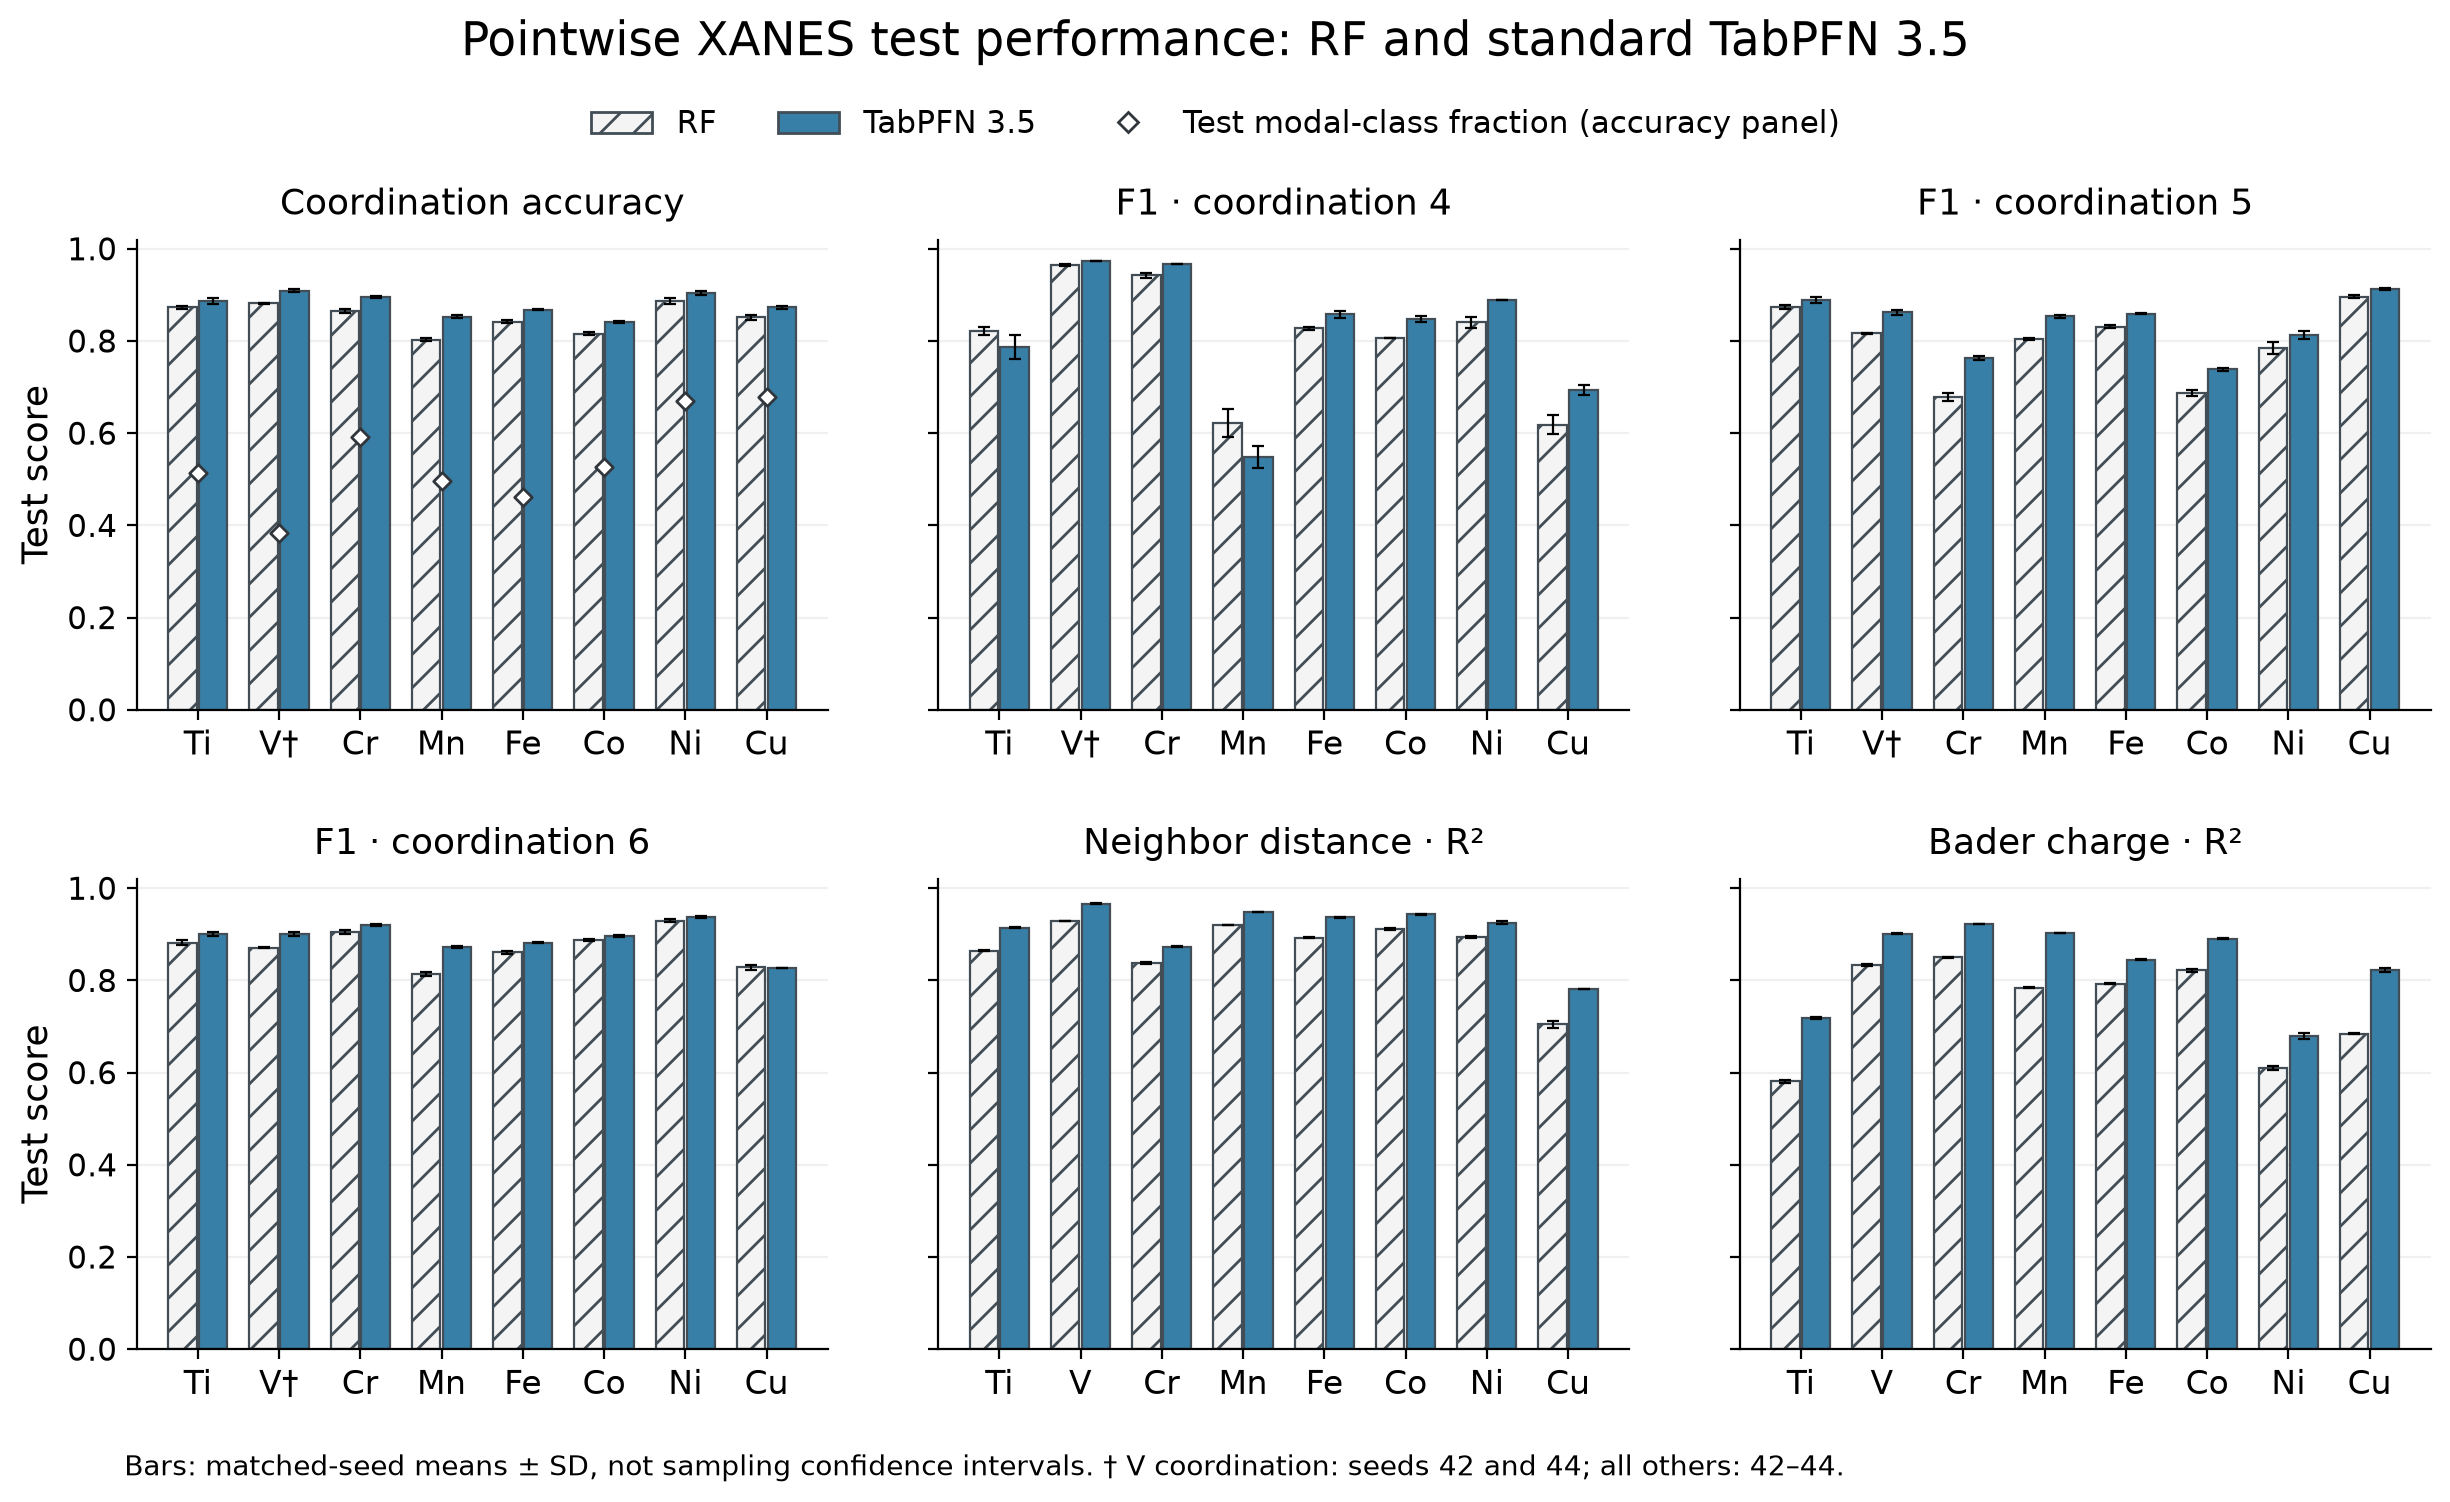

In [4]:
display(Image(filename=str(FIGURES / 'figure_02_test_performance.png')))

**Mixed classification outcomes matter.** CN = 4 F1 decreased for Ti (approximately 0.822 → 0.787) and Mn (0.623 → 0.549), despite higher overall accuracy. Gains in aggregate metrics need not improve every class. Error bars above describe model seeds, not confidence intervals over materials.

## Which energy regions matter?

**Importance = original macro-F1 − macro-F1 after regional shuffling.** We jointly permute the ten channels in one contiguous energy window across validation spectra, preserving the within-window shape while disrupting its association with the target and other regions. Both models receive identical donor orders. Larger positive bars indicate greater measured loss of predictive performance. Negative effects are retained.

The gray strip shows where absorption maxima occur across validation spectra. It is a different quantity from importance. Cr averages three donor shuffles; the other seven comparisons use one matched shuffle. A single highest bar is not necessarily a stable winner.

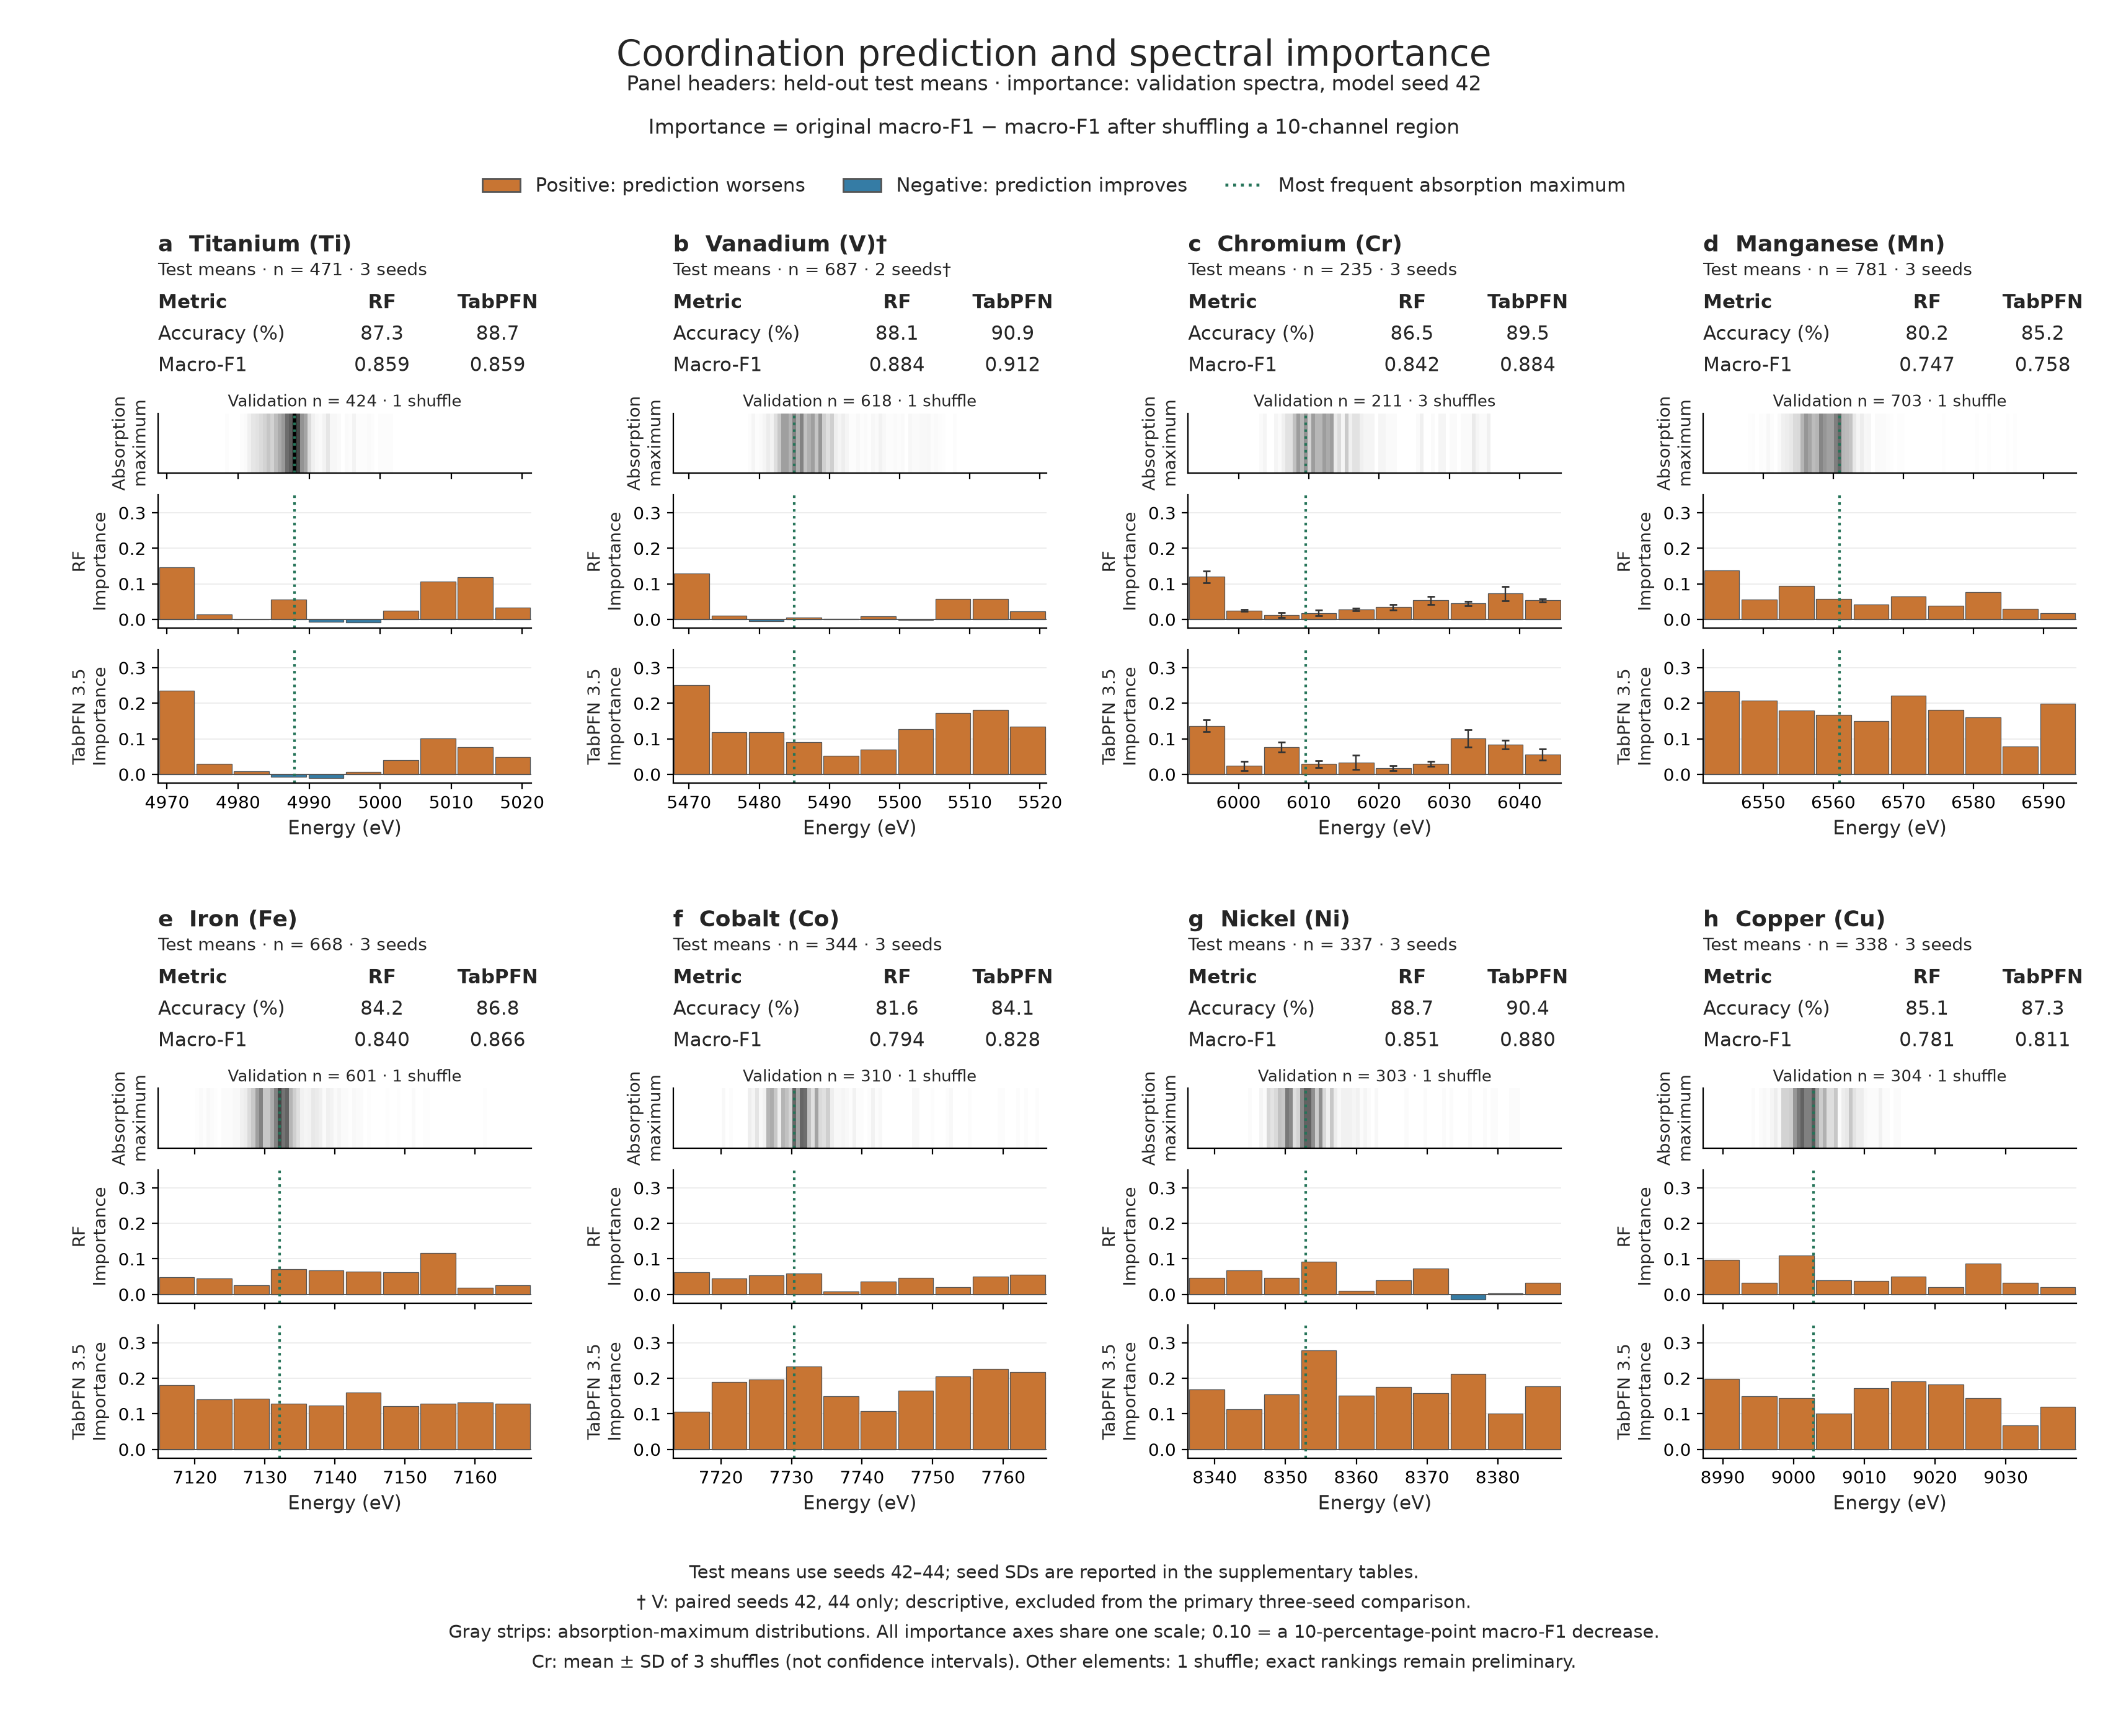

In [5]:
display(Image(filename=str(FIGURES / 'figure_01_coordination_comparison.png')))

In [6]:
display(importance_table().round(4))

,Element,Model,Shuffles,Top_region_eV,Macro_F1_decrease,Modal_maximum_eV
0,Ti,rf,1,4969.0–4973.7,0.1459,4987.9178
1,Ti,tabpfn,1,4969.0–4973.7,0.2352,4987.9178
2,V,rf,1,5468.0–5472.8,0.1293,5485.0120
3,V,tabpfn,1,5468.0–5472.8,0.2520,5485.0120
4,Cr,rf,3,5993.1–5997.9,0.1196,6009.5663
5,Cr,tabpfn,3,5993.1–5997.9,0.1364,6009.5663
6,Mn,rf,1,6541.7–6546.5,0.1382,6560.8698
7,Mn,tabpfn,1,6541.7–6546.5,0.2335,6560.8698
8,Fe,rf,1,7152.3–7157.1,0.1166,7132.0550
9,Fe,tabpfn,1,7115.0–7119.8,0.1818,7132.0550


For **Ti, V, Cr and Mn**, both models' largest observed effects lie below the modal absorption maximum. RF and TabPFN share the highest measured window for five elements; they differ for Fe, Co and Cu. These are **model-sensitivity observations**, not transformer weights or causal mechanisms. Absorption maxima, absorption edges and first peaks are distinct concepts; the result does not contradict spectroscopy theory.

### How stable are those rankings?

A conditional check resamples the saved validation rows 1,000 times, preserving class counts. It keeps the fitted models and donor permutations fixed. The table below shows how often the originally highest window remains among the highest under those row resamples. **These are not confidence levels or new-shuffle stability estimates.**

In [7]:
import json
stability = json.loads((ROOT / 'results/conditional_stability.json').read_text())
s = pd.DataFrame(stability['rows'])
display(s.pivot(index='element', columns='model', values='observed_top_retained_fraction').reindex(['Ti','V','Cr','Mn','Fe','Co','Ni','Cu']).mul(100).round(1).rename(columns={'rf':'RF top retained (%)','tabpfn':'TabPFN top retained (%)'}))

model,RF top retained (%),TabPFN top retained (%)
element,,
Ti,67.3,100.0
V,99.9,99.9
Cr,96.5,90.3
Mn,78.9,47.4
Fe,96.1,75.9
Co,34.8,45.4
Ni,51.8,78.2
Cu,52.2,37.9


Ti and V TabPFN rankings are comparatively stable in this conditional check. Mn, Co and Cu are less stable; close bars should be described as a group of influential regions. Additional donor shuffles would test sensitivity to the chosen permutation. They are not part of this released comparison; exact rankings remain preliminary.

## Regression parity

Each point is one archived test spectrum, using model seed 42. Both models use identical rows and axes. The dashed line denotes prediction = reference; tables report element-specific MAE. Results across all three seeds are in the earlier tables.

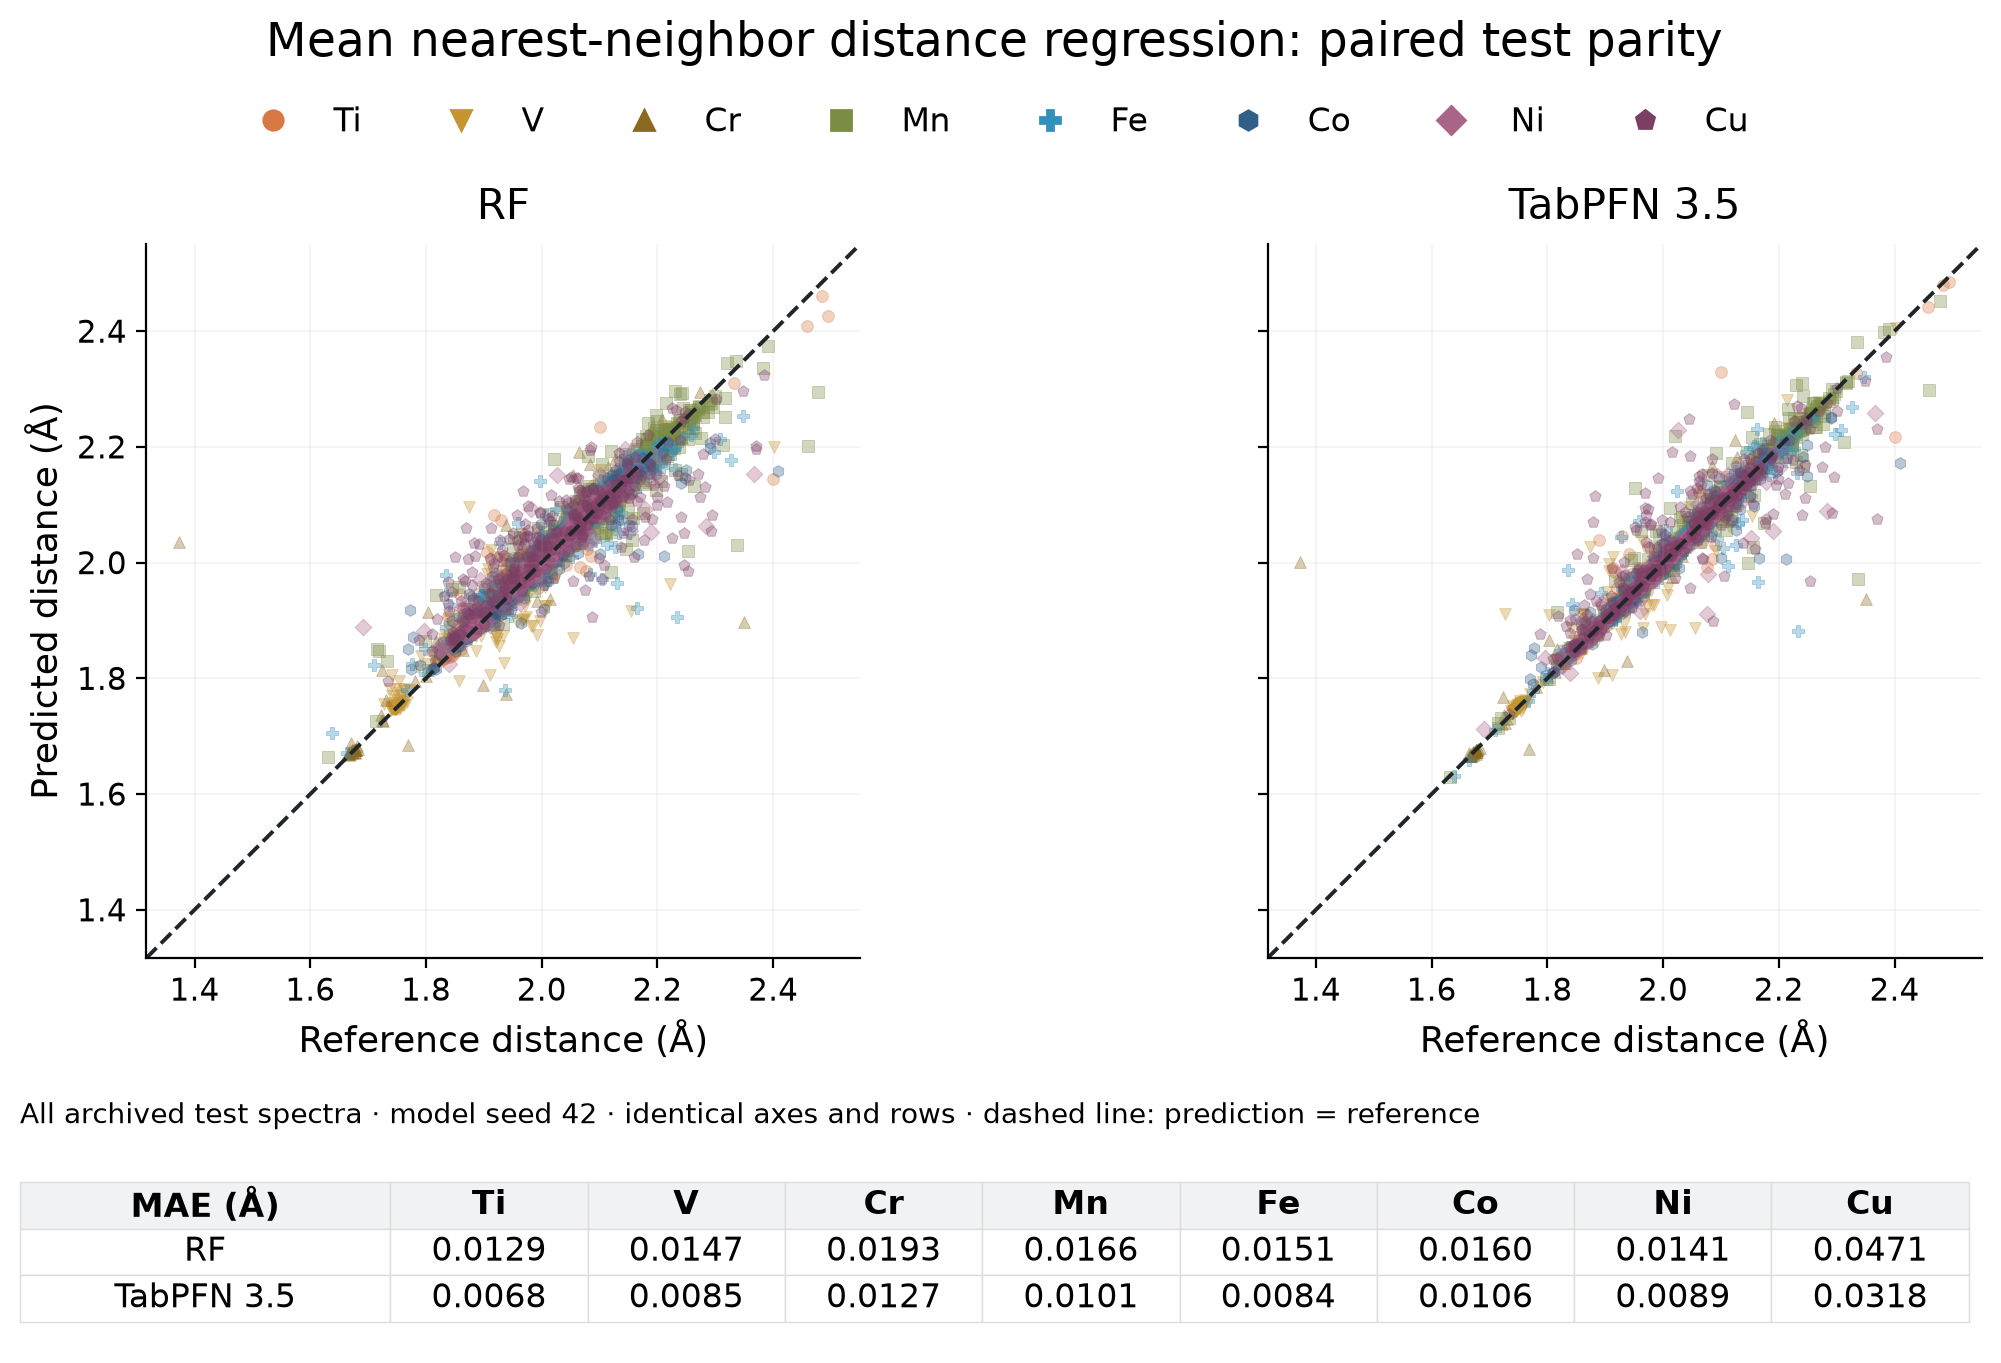

In [8]:
display(Image(filename=str(FIGURES / 'figure_03_distance_parity.png')))

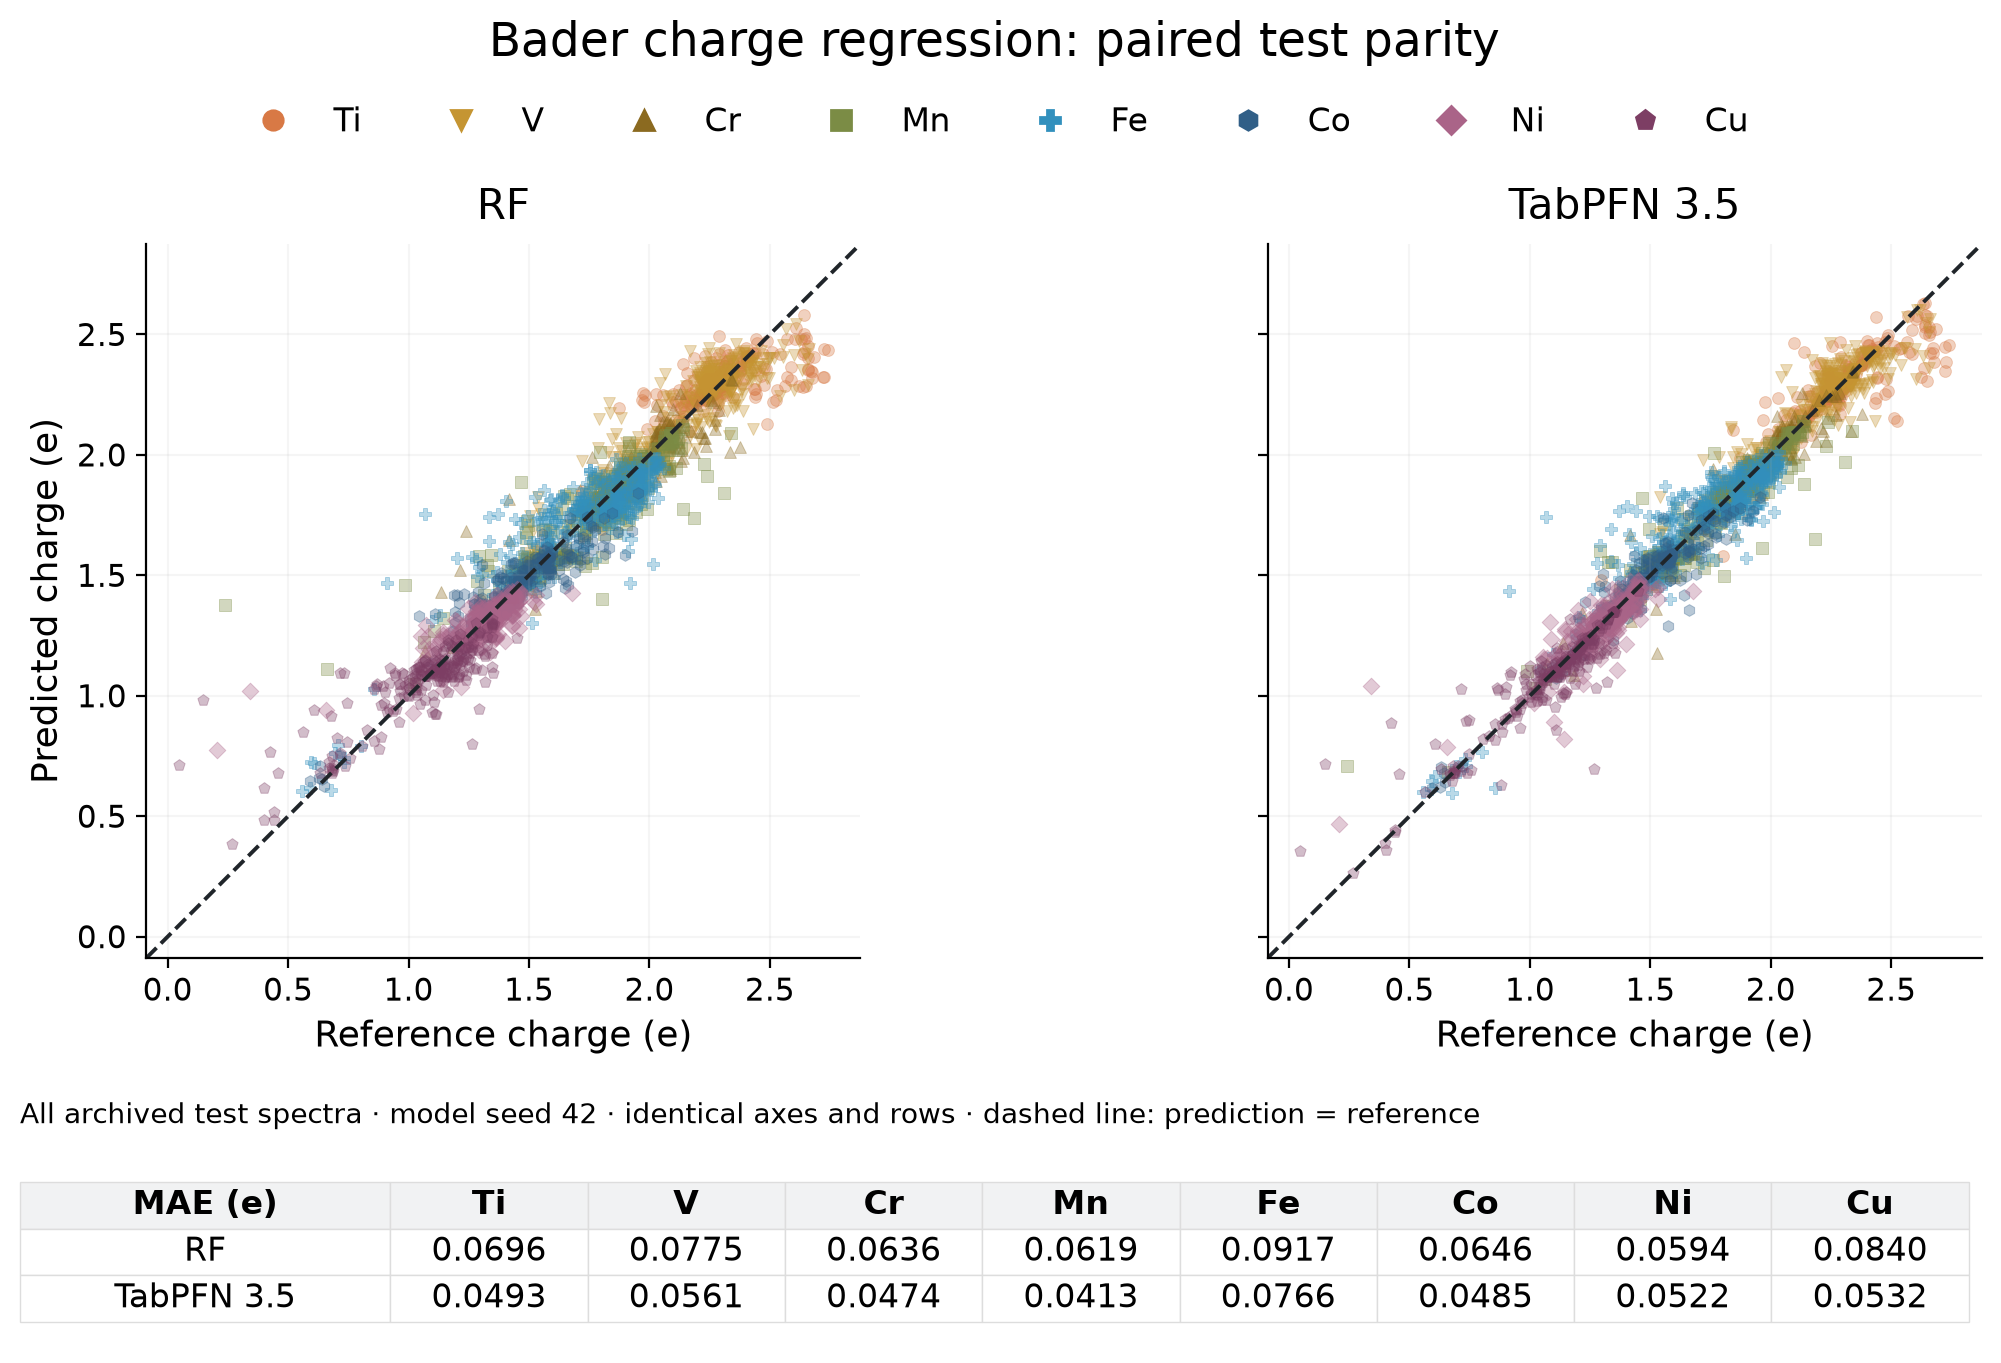

In [9]:
display(Image(filename=str(FIGURES / 'figure_04_bader_parity.png')))

## Scope and next steps

This comparison supports improved regression performance on the original benchmark relative to its fixed RF configuration. It does not establish superiority over tuned RF or modern boosting, generalization to unseen materials, experimental-spectrum performance, or an architectural explanation for TabPFN's gains. Correlated channels and off-distribution shuffled spectra limit the interpretation of permutation importance. Pretraining overlap is uncertain.

Repeated donor shuffles are the immediate check before emphasizing exact importance rankings. Grouped material splits and stronger tuned baselines are separate extensions. See [methods and limitations](../docs/METHODS.md) and [reproducibility](../docs/REPRODUCIBILITY.md).